# AgentWeather - Exploratory Data Analysis

Day 7: Temperature, AQI, Humidity | Day 8: Rain, UV, Wind | Day 9: Correlation and final report

In [1]:
# import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# load dataset
DATA_PATH = "../data/processed/clean_weather.csv"

df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True,
    errors="coerce"
).dt.tz_convert("Asia/Karachi")

df = df.sort_values("timestamp")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2161, 17)


,timestamp,temperature,humidity,precipitation,rain_probability,uv_index,wind_speed,wind_direction,AQI,PM2.5,PM10,O3,NO2,SO2,CO,weather_type,aqi_type
0,2026-08-10 05:00:00+05:00,28.4,88,0.0,NaN,0.00,0.85,135,157.0,157.0,55.0,10.0,58.0,19.0,13.0,historical_reanalysis,historical_model
1,2026-08-10 06:00:00+05:00,28.3,89,0.0,NaN,0.10,0.87,167,159.0,159.0,57.0,9.0,45.0,19.0,12.0,historical_reanalysis,historical_model
2,2026-08-10 07:00:00+05:00,28.8,86,0.0,NaN,0.60,0.21,135,161.0,161.0,59.0,10.0,28.0,18.0,11.0,historical_reanalysis,historical_model
3,2026-08-10 08:00:00+05:00,30.0,81,0.0,NaN,1.50,0.40,90,163.0,163.0,60.0,15.0,15.0,17.0,10.0,historical_reanalysis,historical_model
4,2026-08-10 09:00:00+05:00,31.1,74,0.1,NaN,3.05,1.08,68,163.0,163.0,60.0,23.0,8.0,15.0,10.0,historical_reanalysis,historical_model


In [2]:
# basic dataset info
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2161 entries, 0 to 2160
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype                       
---  ------            --------------  -----                       
 0   timestamp         2161 non-null   datetime64[ns, Asia/Karachi]
 1   temperature       2161 non-null   float64                     
 2   humidity          2161 non-null   int64                       
 3   precipitation     2161 non-null   float64                     
 4   rain_probability  1 non-null      float64                     
 5   uv_index          2161 non-null   float64                     
 6   wind_speed        2161 non-null   float64                     
 7   wind_direction    2161 non-null   int64                       
 8   AQI               2160 non-null   float64                     
 9   PM2.5             2160 non-null   float64                     
 10  PM10              2160 non-null   float64          

,temperature,humidity,precipitation,rain_probability,uv_index,wind_speed,wind_direction,AQI,PM2.5,PM10,O3,NO2,SO2,CO
count,2161.000000,2161.000000,2161.000000,1.0,2161.000000,2161.000000,2161.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,27.831416,70.355854,0.081212,0.0,1.347270,1.367154,171.936603,159.476852,153.919907,65.601852,72.259259,20.337963,9.734722,13.204167
std,4.536426,15.422467,0.552937,NaN,2.069762,0.740730,99.450319,25.034010,22.544826,13.999166,62.314086,15.700699,3.146051,7.772619
min,16.500000,31.000000,0.000000,0.0,0.000000,0.000000,0.000000,77.000000,77.000000,23.000000,0.000000,0.000000,3.000000,3.000000
25%,24.700000,58.000000,0.000000,0.0,0.000000,0.890000,90.000000,149.000000,145.000000,56.000000,24.000000,7.000000,7.000000,8.000000
50%,28.200000,73.000000,0.000000,0.0,0.000000,1.280000,143.000000,159.000000,156.000000,65.000000,42.000000,16.000000,9.000000,11.000000
75%,31.200000,83.000000,0.000000,0.0,2.300000,1.720000,270.000000,170.000000,165.000000,74.000000,118.000000,32.000000,12.000000,16.000000
max,38.000000,100.000000,9.900000,0.0,7.900000,7.490000,360.000000,229.000000,215.000000,102.000000,229.000000,73.000000,20.000000,55.000000



Missing Values:


timestamp              0
temperature            0
humidity               0
precipitation          0
rain_probability    2160
uv_index               0
wind_speed             0
wind_direction         0
AQI                    1
PM2.5                  1
PM10                   1
O3                     1
NO2                    1
SO2                    1
CO                     1
weather_type           0
aqi_type               0
dtype: int64

## Day 7 - Temperature, AQI and Humidity

In [3]:
# avg,max and min temperature
avg_temp = df["temperature"].mean()
max_temp = df["temperature"].max()
min_temp = df["temperature"].min()

print("TEMPERATURE ANALYSIS")
print("--------------------")

print(f"Average Temperature: {avg_temp:.2f} °C")
print(f"Maximum Temperature: {max_temp:.2f} °C")
print(f"Minimum Temperature: {min_temp:.2f} °C")

TEMPERATURE ANALYSIS
--------------------
Average Temperature: 27.83 °C
Maximum Temperature: 38.00 °C
Minimum Temperature: 16.50 °C


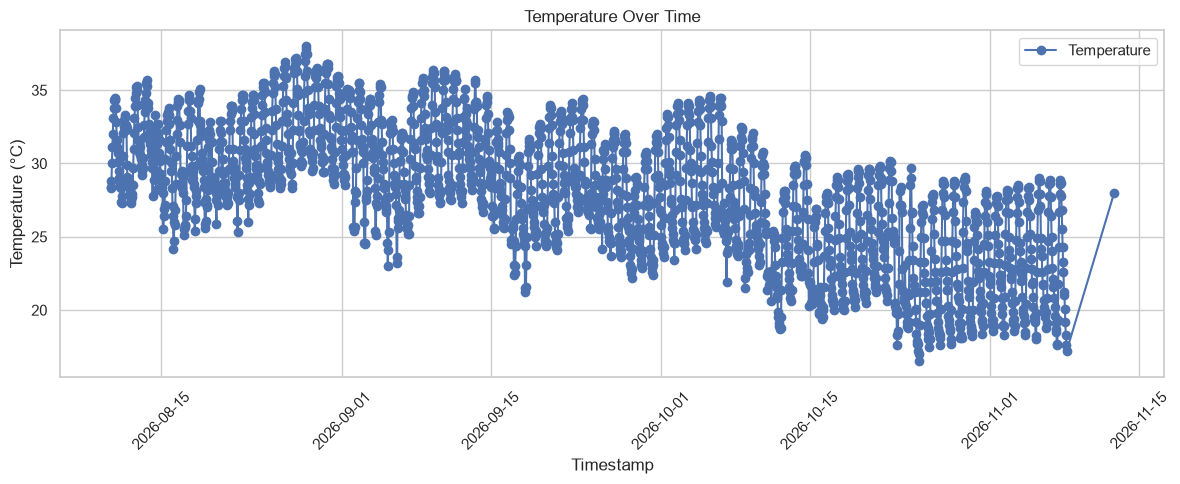

In [4]:
# hourly temperature graph
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["temperature"],
    marker="o",
    label="Temperature"
)

plt.title("Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

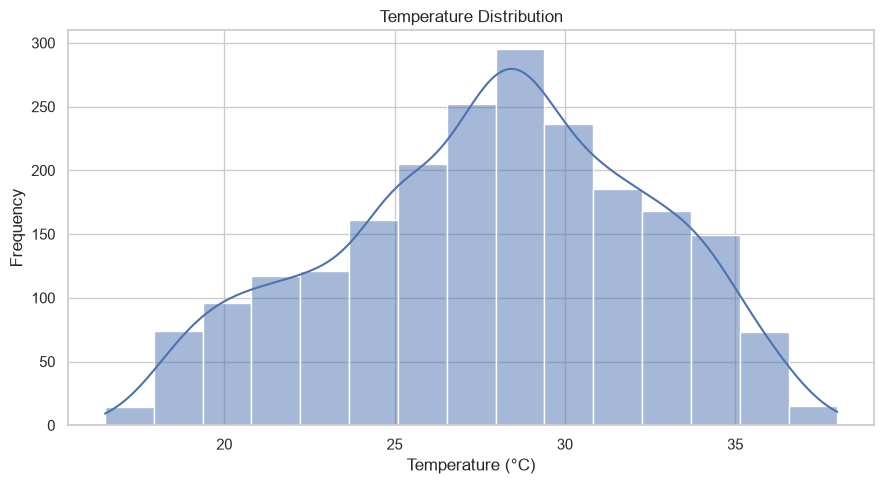

In [5]:
# temperature distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="temperature",
    bins=15,
    kde=True
)

plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [6]:
# avergae and highest aqi
avg_aqi = df["AQI"].mean()
max_aqi = df["AQI"].max()
min_aqi = df["AQI"].min()

print("AIR QUALITY ANALYSIS")
print("--------------------")

print(f"Average AQI: {avg_aqi:.2f}")
print(f"Highest AQI: {max_aqi:.2f}")
print(f"Lowest AQI: {min_aqi:.2f}")

AIR QUALITY ANALYSIS
--------------------
Average AQI: 159.48
Highest AQI: 229.00
Lowest AQI: 77.00


In [7]:
# aqi categories distribution
def classify_aqi(aqi):

    if pd.isna(aqi):
        return np.nan

    if aqi <= 50:
        return "Good"

    elif aqi <= 100:
        return "Moderate"

    elif aqi <= 150:
        return "Unhealthy for Sensitive Groups"

    elif aqi <= 200:
        return "Unhealthy"

    elif aqi <= 300:
        return "Very Unhealthy"

    else:
        return "Hazardous"


df["AQI_Category"] = df["AQI"].apply(
    classify_aqi
)

print("AQI Category Distribution:")

display(
    df["AQI_Category"].value_counts()
)

AQI Category Distribution:


AQI_Category
Unhealthy                         1419
Unhealthy for Sensitive Groups     545
Very Unhealthy                     148
Moderate                            48
Name: count, dtype: int64

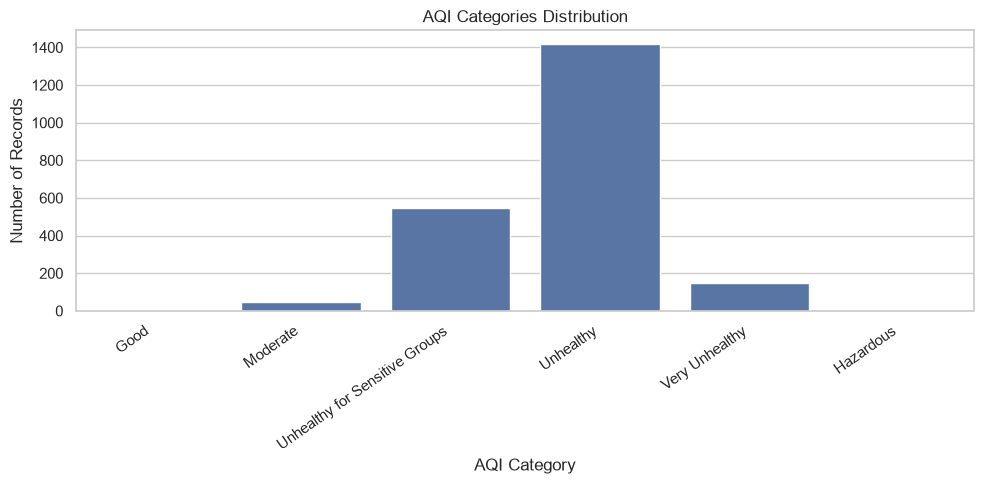

In [8]:
# aqi category graph
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="AQI_Category",
    order=[
        "Good",
        "Moderate",
        "Unhealthy for Sensitive Groups",
        "Unhealthy",
        "Very Unhealthy",
        "Hazardous"
    ]
)

plt.title("AQI Categories Distribution")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.show()

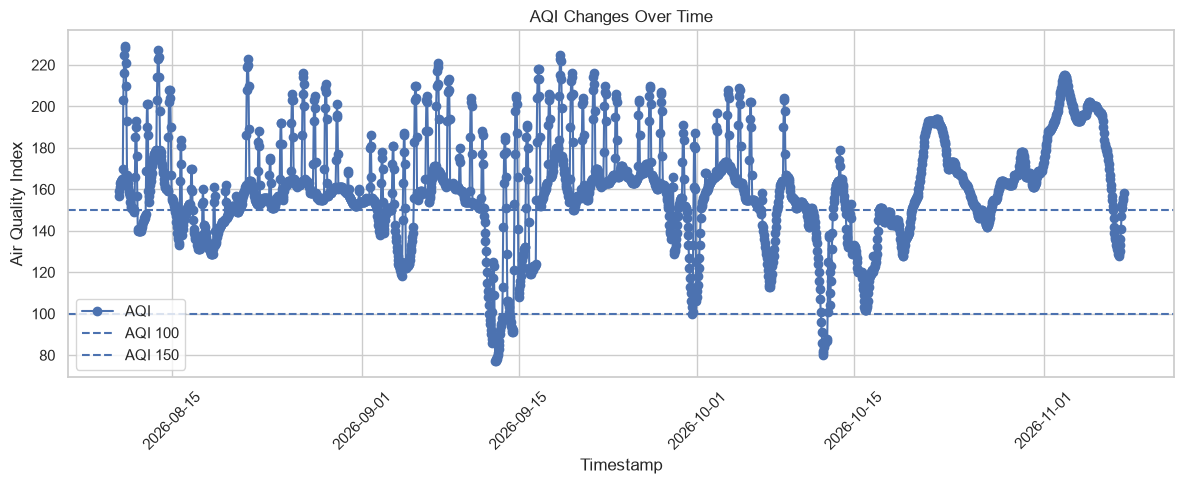

In [9]:
# aqi time series graph
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["AQI"],
    marker="o",
    label="AQI"
)

plt.axhline(
    y=100,
    linestyle="--",
    label="AQI 100"
)

plt.axhline(
    y=150,
    linestyle="--",
    label="AQI 150"
)

plt.title("AQI Changes Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Air Quality Index")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
# avergae min and max humidity
avg_humidity = df["humidity"].mean()
max_humidity = df["humidity"].max()
min_humidity = df["humidity"].min()

print("HUMIDITY ANALYSIS")
print("-----------------")

print(f"Average Humidity: {avg_humidity:.2f}%")
print(f"Maximum Humidity: {max_humidity:.2f}%")
print(f"Minimum Humidity: {min_humidity:.2f}%")

HUMIDITY ANALYSIS
-----------------
Average Humidity: 70.36%
Maximum Humidity: 100.00%
Minimum Humidity: 31.00%


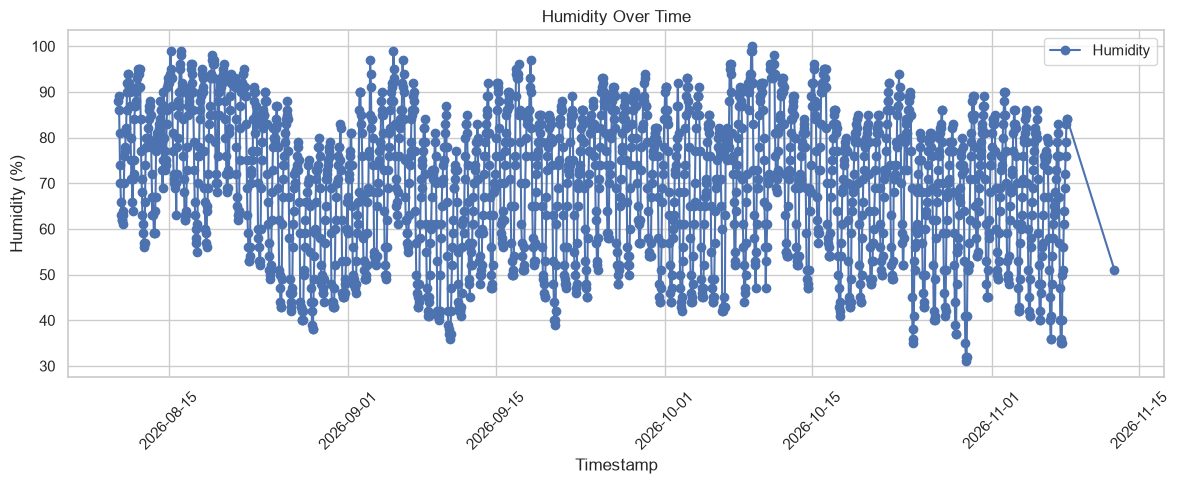

In [11]:
# hourly humidity graph
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["humidity"],
    marker="o",
    label="Humidity"
)

plt.title("Humidity Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Humidity (%)")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

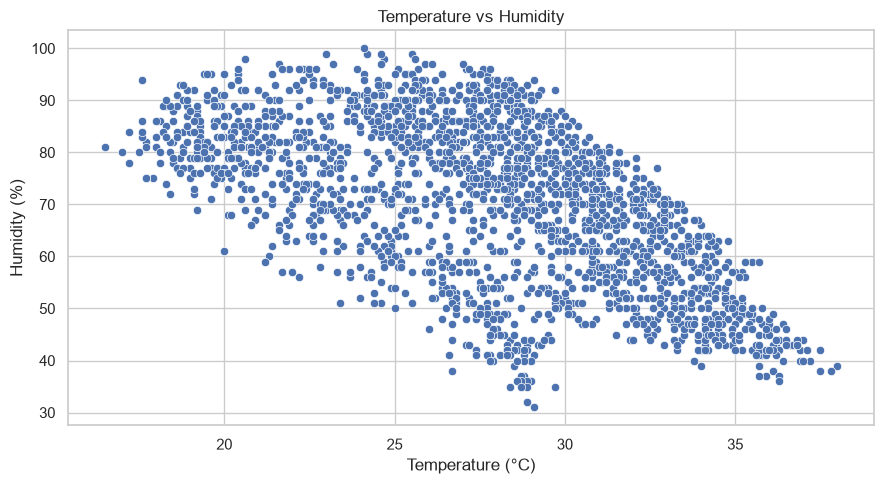

In [12]:
# temperature vs humidity relationship
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="temperature",
    y="humidity"
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")

plt.tight_layout()
plt.show()

In [13]:
# automatic observation
print("=" * 45)
print("       DAY 7 - EDA OBSERVATIONS")
print("=" * 45)

print("\n1. TEMPERATURE")

print(f"Average: {df['temperature'].mean():.2f} °C")
print(f"Maximum: {df['temperature'].max():.2f} °C")
print(f"Minimum: {df['temperature'].min():.2f} °C")

print("\n2. AIR QUALITY")

print(f"Average AQI: {df['AQI'].mean():.2f}")
print(f"Highest AQI: {df['AQI'].max():.2f}")

if df["AQI_Category"].notna().any():
    print(
        "Most common AQI category:",
        df["AQI_Category"].mode().iloc[0]
    )

print("\n3. HUMIDITY")

print(f"Average: {df['humidity'].mean():.2f}%")
print(f"Maximum: {df['humidity'].max():.2f}%")
print(f"Minimum: {df['humidity'].min():.2f}%")

correlation = df[
    ["temperature", "humidity"]
].corr().iloc[0, 1]

print("\n4. TEMPERATURE-HUMIDITY RELATIONSHIP")
print(f"Correlation: {correlation:.3f}")

if pd.isna(correlation):
    print("Insufficient data for correlation analysis.")

elif correlation > 0:
    print("Positive linear relationship.")

elif correlation < 0:
    print("Negative linear relationship.")

else:
    print("No linear relationship detected.")

print("\nTotal observations:", len(df))

       DAY 7 - EDA OBSERVATIONS

1. TEMPERATURE
Average: 27.83 °C
Maximum: 38.00 °C
Minimum: 16.50 °C

2. AIR QUALITY
Average AQI: 159.48
Highest AQI: 229.00
Most common AQI category: Unhealthy

3. HUMIDITY
Average: 70.36%
Maximum: 100.00%
Minimum: 31.00%

4. TEMPERATURE-HUMIDITY RELATIONSHIP
Correlation: -0.590
Negative linear relationship.

Total observations: 2161


In [14]:
# save your graph
PLOT_DIR = "../data/processed/eda_plots"

os.makedirs(PLOT_DIR, exist_ok=True)

# Temperature over time
plt.figure(figsize=(12, 5))
plt.plot(df["timestamp"], df["temperature"], marker="o")
plt.title("Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/temperature_time_series.png")
plt.close()

# Temperature distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="temperature", kde=True)
plt.title("Temperature Distribution")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/temperature_distribution.png")
plt.close()

# AQI over time
plt.figure(figsize=(12, 5))
plt.plot(df["timestamp"], df["AQI"], marker="o")
plt.title("AQI Over Time")
plt.xlabel("Timestamp")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/aqi_time_series.png")
plt.close()

# AQI categories
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="AQI_Category")
plt.title("AQI Categories Distribution")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/aqi_categories.png")
plt.close()

# Humidity over time
plt.figure(figsize=(12, 5))
plt.plot(df["timestamp"], df["humidity"], marker="o")
plt.title("Humidity Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/humidity_time_series.png")
plt.close()

# Temperature vs Humidity
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="temperature", y="humidity")
plt.title("Temperature vs Humidity")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/temperature_humidity.png")
plt.close()

print("All EDA graphs saved successfully!")

All EDA graphs saved successfully!


## Day 8 - Rain, UV Index and Wind

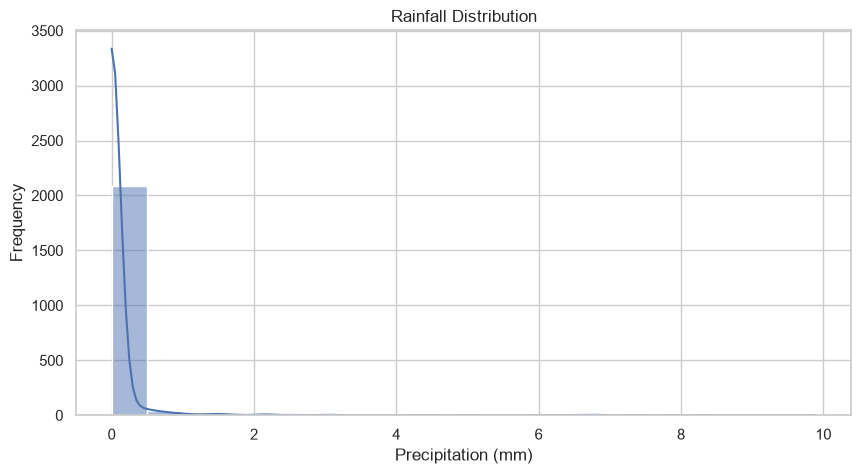

In [15]:
# rainfall distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="precipitation",
    bins=20,
    kde=True
)

plt.title("Rainfall Distribution")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")

plt.show()

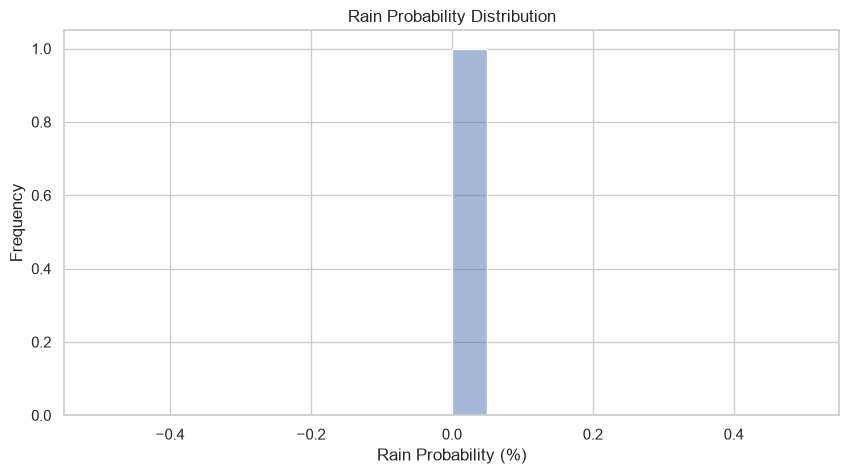

In [16]:
# rain probability
if df["rain_probability"].notna().any():

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x="rain_probability",
        bins=20,
        kde=True
    )

    plt.title("Rain Probability Distribution")
    plt.xlabel("Rain Probability (%)")
    plt.ylabel("Frequency")

    plt.show()

else:
    print("Rain probability data is not available.")

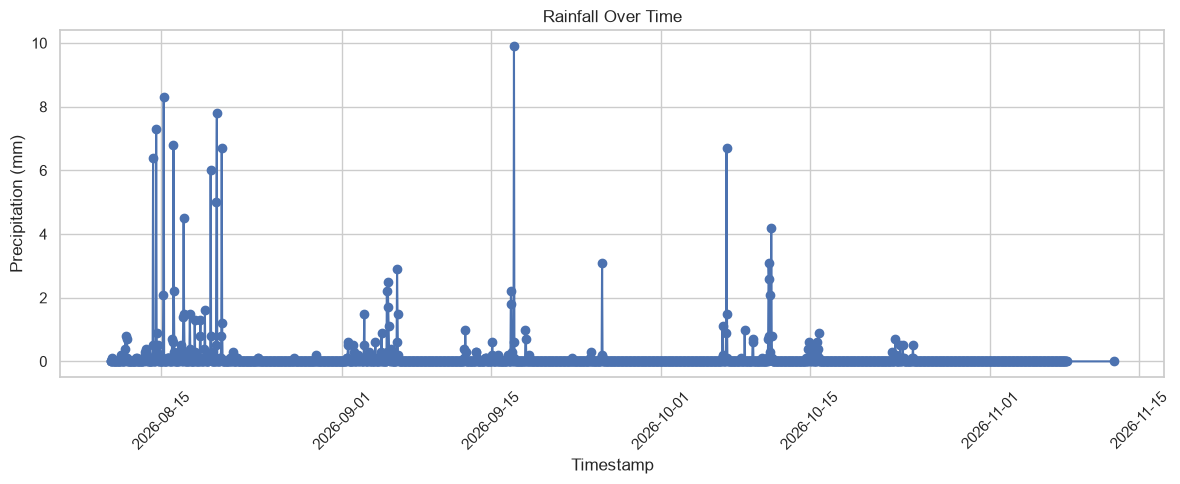

In [17]:
# rainfall overtime
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["precipitation"],
    marker="o"
)

plt.title("Rainfall Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Precipitation (mm)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

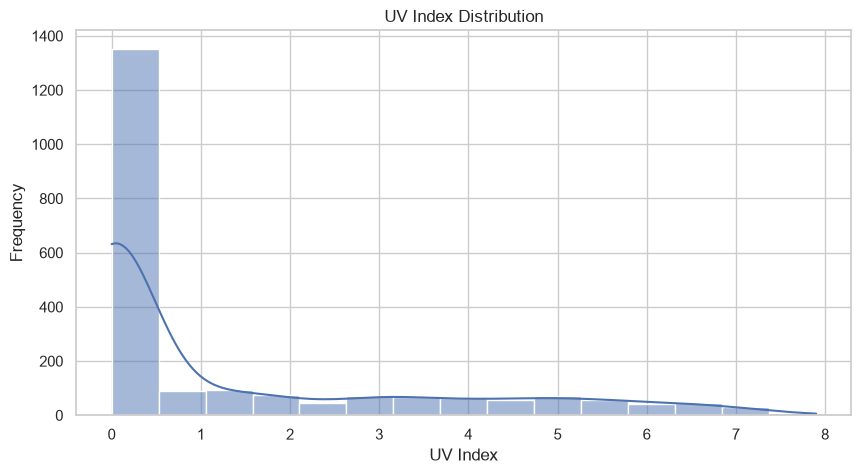

In [18]:
# uv distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="uv_index",
    bins=15,
    kde=True
)

plt.title("UV Index Distribution")
plt.xlabel("UV Index")
plt.ylabel("Frequency")

plt.show()

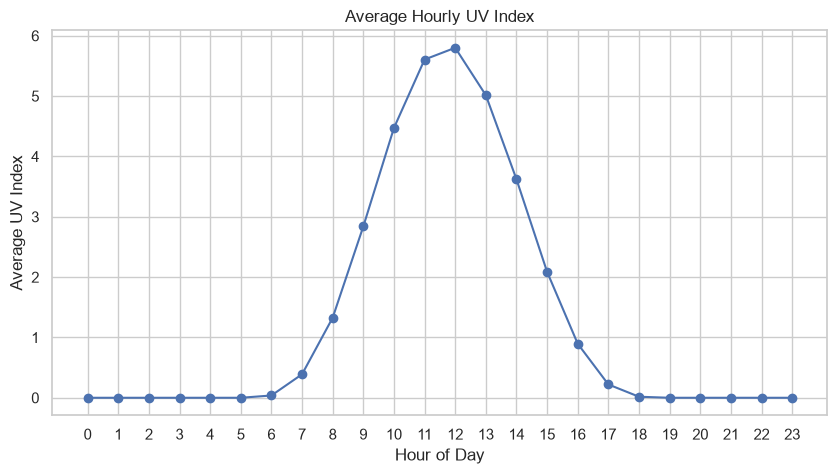

In [19]:
# hourly uv changes
df["hour"] = df["timestamp"].dt.hour

hourly_uv = df.groupby(
    "hour"
)["uv_index"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_uv.index,
    hourly_uv.values,
    marker="o"
)

plt.title("Average Hourly UV Index")
plt.xlabel("Hour of Day")
plt.ylabel("Average UV Index")

plt.xticks(range(0, 24))
plt.show()

In [20]:
# highest uv hours
highest_uv = hourly_uv.sort_values(
    ascending=False
)

print("Highest UV Hours:")
print(highest_uv.head(5))

Highest UV Hours:
hour
12    5.800556
11    5.605556
13    5.014444
10    4.471667
14    3.621111
Name: uv_index, dtype: float64


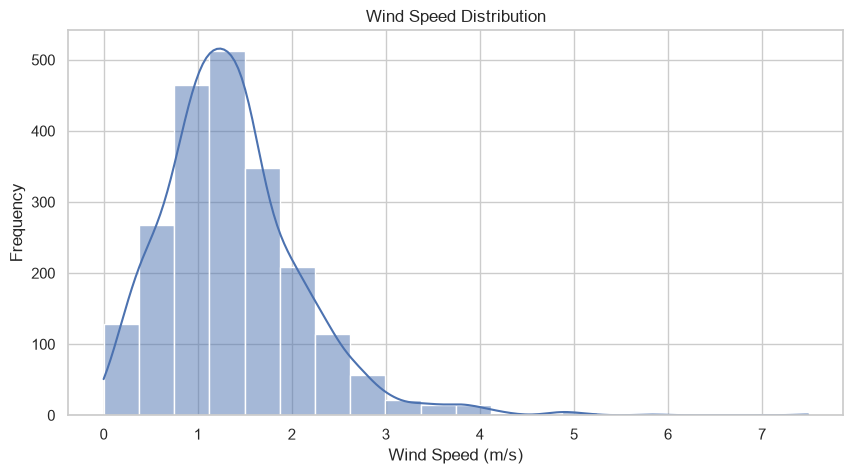

In [21]:
# wind speed distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="wind_speed",
    bins=20,
    kde=True
)

plt.title("Wind Speed Distribution")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Frequency")

plt.show()

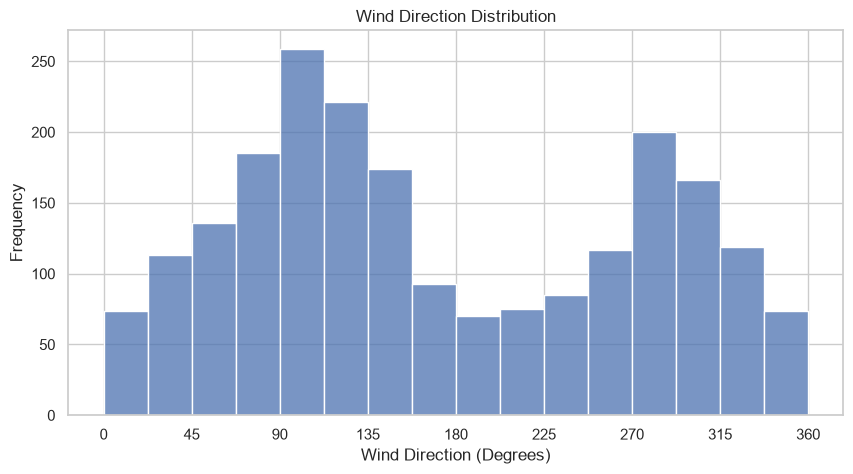

In [22]:
# wind direction distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="wind_direction",
    bins=16
)

plt.title("Wind Direction Distribution")
plt.xlabel("Wind Direction (Degrees)")
plt.ylabel("Frequency")

plt.xticks(range(0, 361, 45))

plt.show()

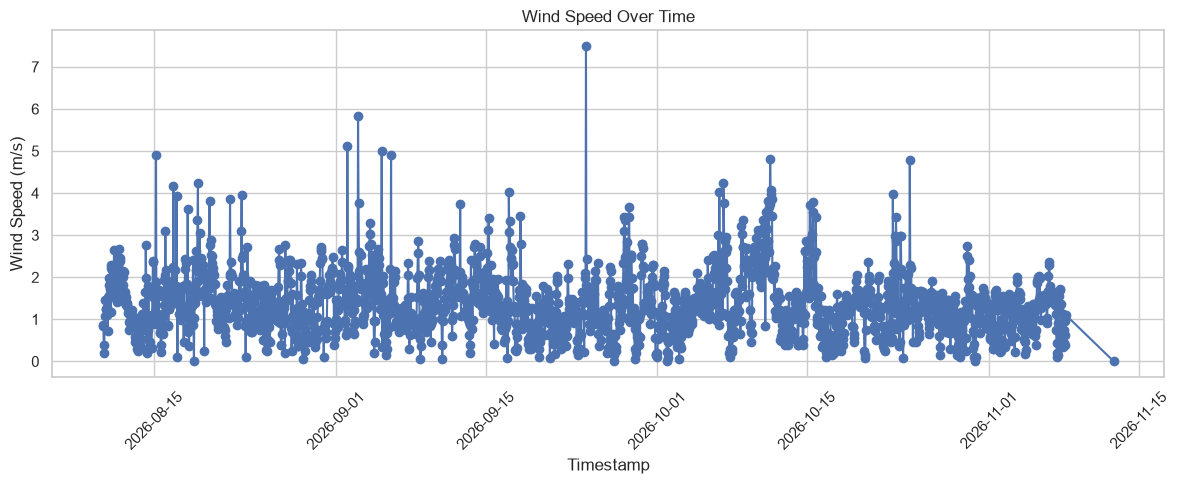

In [23]:
# wind speed overtime
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["wind_speed"],
    marker="o"
)

plt.title("Wind Speed Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Wind Speed (m/s)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [24]:
# statistical summary
columns = [
    "precipitation",
    "rain_probability",
    "uv_index",
    "wind_speed",
    "wind_direction"
]

print("Weather Statistical Summary:")

print(
    df[columns].describe()
)

Weather Statistical Summary:
       precipitation  rain_probability     uv_index   wind_speed  \
count    2161.000000               1.0  2161.000000  2161.000000   
mean        0.081212               0.0     1.347270     1.367154   
std         0.552937               NaN     2.069762     0.740730   
min         0.000000               0.0     0.000000     0.000000   
25%         0.000000               0.0     0.000000     0.890000   
50%         0.000000               0.0     0.000000     1.280000   
75%         0.000000               0.0     2.300000     1.720000   
max         9.900000               0.0     7.900000     7.490000   

       wind_direction  
count     2161.000000  
mean       171.936603  
std         99.450319  
min          0.000000  
25%         90.000000  
50%        143.000000  
75%        270.000000  
max        360.000000  


## Day 9 - Correlation and Final EDA Report

In [25]:
# Main six metrics
metrics = [
    "temperature",
    "AQI",
    "humidity",
    "precipitation",
    "uv_index",
    "wind_speed"
]

# Only available columns
available_metrics = [
    col for col in metrics if col in df.columns
]

print("Available metrics:", available_metrics)

Available metrics: ['temperature', 'AQI', 'humidity', 'precipitation', 'uv_index', 'wind_speed']


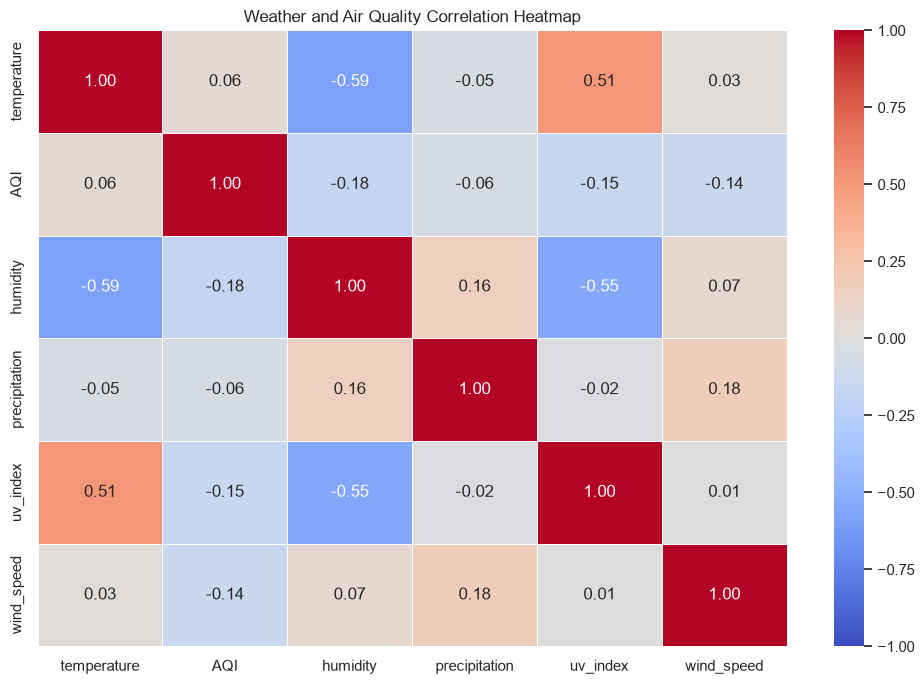

In [26]:
# correlation heatmao
correlation = df[available_metrics].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Weather and Air Quality Correlation Heatmap")
plt.tight_layout()
plt.show()

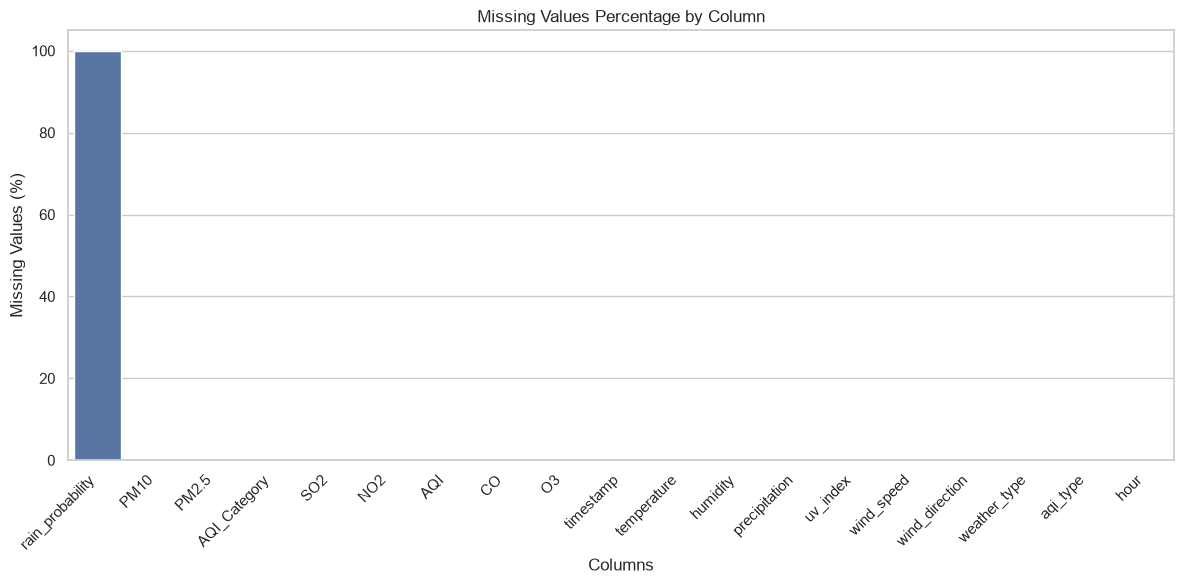

Missing Value Percentage:


,Missing %
rain_probability,99.953725
PM10,0.046275
PM2.5,0.046275
AQI_Category,0.046275
SO2,0.046275
NO2,0.046275
AQI,0.046275
CO,0.046275
O3,0.046275
timestamp,0.000000


In [27]:
# missing value percentage chart
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_percentage.index,
    y=missing_percentage.values
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

print("Missing Value Percentage:")
display(missing_percentage.to_frame("Missing %"))

In [28]:
# outliers analysis using iqr
outlier_results = []

for col in available_metrics:

    values = df[col].dropna()

    if len(values) < 4:
        print(f"Skipping {col}: insufficient observations")
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    outliers = values[
        (values < lower_limit) |
        (values > upper_limit)
    ]

    outlier_results.append({
        "Metric": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(values)
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Metric,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,temperature,14.950,40.950,0,0.000000
1,AQI,117.500,201.500,241,11.157407
2,humidity,20.500,120.500,0,0.000000
3,precipitation,0.000,0.000,220,10.180472
4,uv_index,-3.450,5.750,124,5.738084
5,wind_speed,-0.355,2.965,64,2.961592


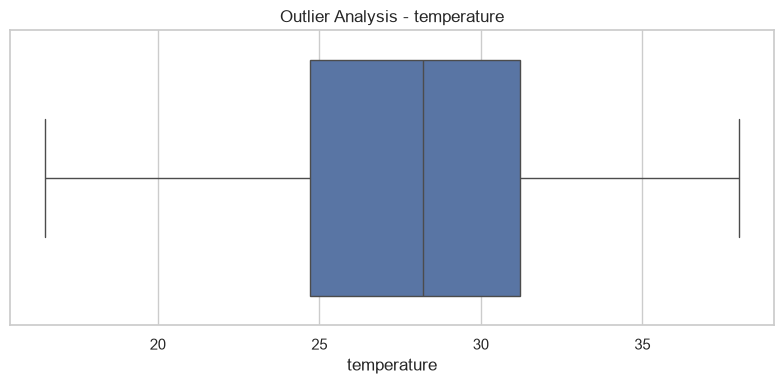

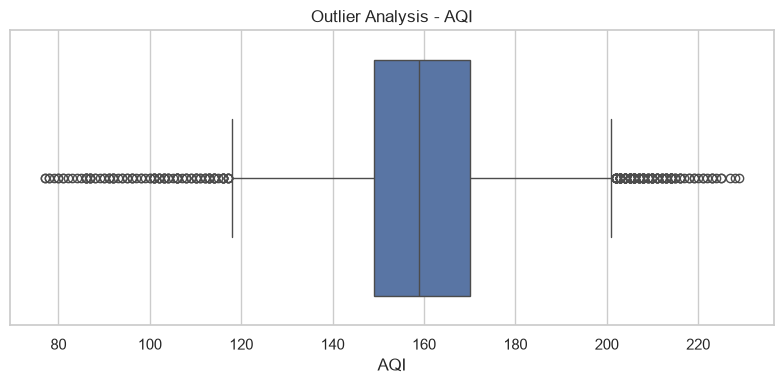

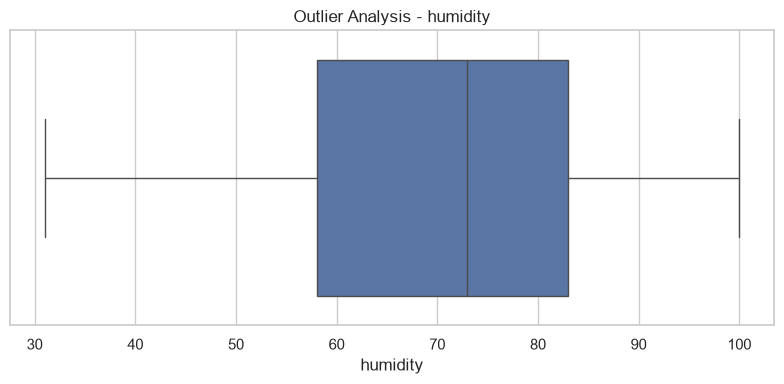

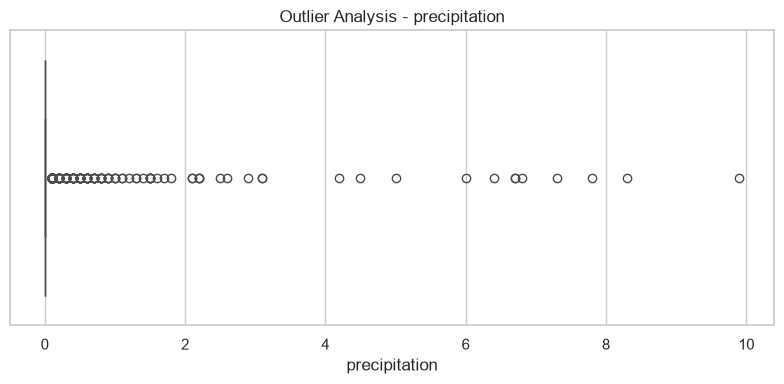

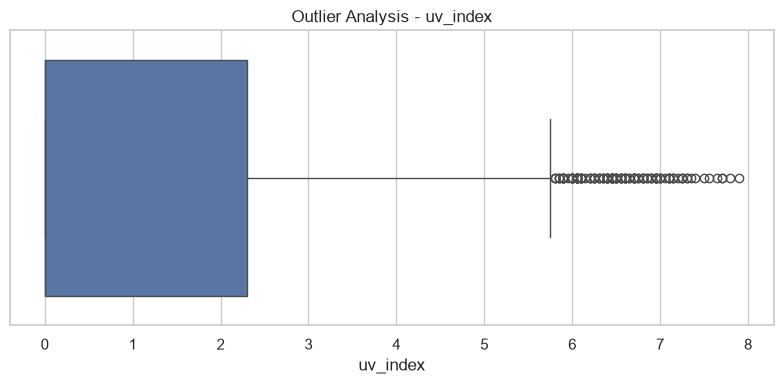

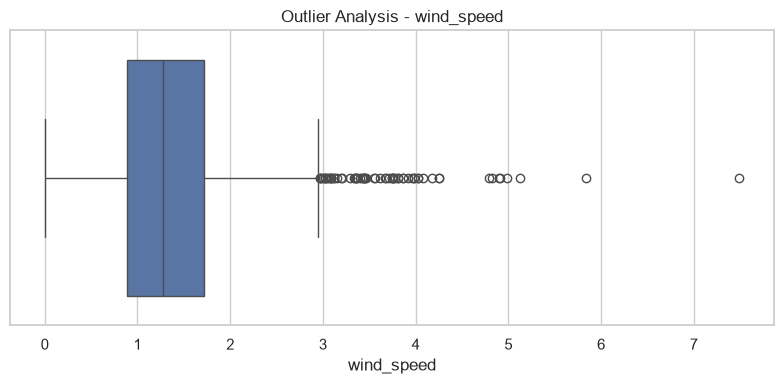

In [29]:
# outliers boxplots
for col in available_metrics:

    values = df[col].dropna()

    if len(values) < 2:
        continue

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=values)

    plt.title(f"Outlier Analysis - {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [30]:
# important statistical summary
display(df[available_metrics].describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature,2161.0,27.831416,4.536426,16.5,24.70,28.20,31.20,38.00
AQI,2160.0,159.476852,25.034010,77.0,149.00,159.00,170.00,229.00
humidity,2161.0,70.355854,15.422467,31.0,58.00,73.00,83.00,100.00
precipitation,2161.0,0.081212,0.552937,0.0,0.00,0.00,0.00,9.90
uv_index,2161.0,1.347270,2.069762,0.0,0.00,0.00,2.30,7.90
wind_speed,2161.0,1.367154,0.740730,0.0,0.89,1.28,1.72,7.49


In [31]:
# important observations of each metric
print("=" * 45)
print("       DAY 9 - EDA OBSERVATIONS")
print("=" * 45)

for col in available_metrics:

    values = df[col].dropna()

    print(f"\n{col.upper()}")

    if values.empty:
        print("No data available.")
        continue

    print(
        f"Average: {values.mean():.2f} | "
        f"Min: {values.min():.2f} | "
        f"Max: {values.max():.2f}"
    )

    print(
        "Highest value at:",
        df.loc[values.idxmax(), "timestamp"].strftime("%Y-%m-%d %H:%M")
    )

    print(f"Missing values: {df[col].isnull().mean() * 100:.1f}%")

# strongest relationship between two metrics
pairs = correlation.where(
    np.triu(np.ones(correlation.shape, dtype=bool), k=1)
).stack()

if not pairs.empty:

    first, second = pairs.abs().idxmax()

    print(
        f"\nStrongest correlation: {first} & {second} "
        f"({correlation.loc[first, second]:.2f})"
    )

       DAY 9 - EDA OBSERVATIONS

TEMPERATURE
Average: 27.83 | Min: 16.50 | Max: 38.00
Highest value at: 2026-08-28 14:00
Missing values: 0.0%

AQI
Average: 159.48 | Min: 77.00 | Max: 229.00
Highest value at: 2026-08-10 18:00
Missing values: 0.0%

HUMIDITY
Average: 70.36 | Min: 31.00 | Max: 100.00
Highest value at: 2026-10-09 06:00
Missing values: 0.0%

PRECIPITATION
Average: 0.08 | Min: 0.00 | Max: 9.90
Highest value at: 2026-09-17 04:00
Missing values: 0.0%

UV_INDEX
Average: 1.35 | Min: 0.00 | Max: 7.90
Highest value at: 2026-09-12 12:00
Missing values: 0.0%

WIND_SPEED
Average: 1.37 | Min: 0.00 | Max: 7.49
Highest value at: 2026-09-24 08:00
Missing values: 0.0%

Strongest correlation: temperature & humidity (-0.59)
